In [4]:
import pandas as pd
churn = pd.read_csv("churn_logistic.csv")
churn.head()

,Account Length,VMail Message,Day Mins,Eve Mins,Night Mins,Intl Mins,CustServ Calls,Intl Plan,VMail Plan,Day Calls,...,Eve Calls,Eve Charge,Night Calls,Night Charge,Intl Calls,Intl Charge,State,Area Code,Phone,Churn
0,128,25,265.1,197.4,244.7,10.0,1,0,1,110,...,99,16.78,91,11.01,3,2.70,KS,415,382-4657,0
1,107,26,161.6,195.5,254.4,13.7,1,0,1,123,...,103,16.62,103,11.45,3,3.70,OH,415,371-7191,0
2,137,0,243.4,121.2,162.6,12.2,0,0,0,114,...,110,10.30,104,7.32,5,3.29,NJ,415,358-1921,0
3,84,0,299.4,61.9,196.9,6.6,2,1,0,71,...,88,5.26,89,8.86,7,1.78,OH,408,375-9999,0
4,75,0,166.7,148.3,186.9,10.1,3,1,0,113,...,122,12.61,121,8.41,3,2.73,OK,415,330-6626,0


In [5]:
churn.columns

Index(['Account Length', 'VMail Message', 'Day Mins', 'Eve Mins', 'Night Mins',
       'Intl Mins', 'CustServ Calls', 'Intl Plan', 'VMail Plan', 'Day Calls',
       'Day Charge', 'Eve Calls', 'Eve Charge', 'Night Calls', 'Night Charge',
       'Intl Calls', 'Intl Charge', 'State', 'Area Code', 'Phone', 'Churn'],
      dtype='object')

In [8]:


# Data Description

# Records	Features
# 5700	21
# Id	Features	Description
# 01	state	2-letter code of the US state of customer residence
# 02	account_length	Number of months the customer has been with the current telco provider
# 03	area_code	string="area_code_AAA" where AAA = 3 digit area code
# 04	intl_plan	The customer has international plan
# 05	vmail_plan	The customer has voice mail plan
# 06	vmail_messages	Number of voice-mail messages
# 07	day_mins	Total minutes of day calls
# 08	day_calls	Total no of day calls
# 09	day_charge	Total charge of day calls
# 10	eve_mins	Total minutes of evening calls
# 11	eve_calls	Total no of evening calls
# 12	eve_charge	Total charge of evening calls
# 13	night_mins	Total minutes of night calls
# 14	night_calls	Total no of night calls
# 15	night_charge	Total charge of night calls
# 16	intl_mins	Total minutes of international calls
# 17	intl_calls	Total no of international calls
# 18	intl_charge	Total charge of international calls
# 19	customer_service_calls	Number of calls to customer service
# 20	phone	10 digit number
# 21	churn	Customer churn - target variable

## Data Description

### Records Features
- 5700 21

### Id Features Description
- 01 state 2-letter code of the US state of customer residence
- 02 account_length Number of months the customer has been with the current telco provider
- 03 area_code string="area_code_AAA" where AAA = 3 digit area code
- 04 intl_plan The customer has an international plan
- 05 vmail_plan The customer has a voicemail plan
- 06 vmail_messages Number of voicemail messages
- 07 day_mins Total minutes of day calls
- 08 day_calls Total number of day calls
- 09 day_charge Total charge of day calls
- 10 eve_mins Total minutes of evening calls
- 11 eve_calls Total number of evening calls
- 12 eve_charge Total charge of evening calls
- 13 night_mins Total minutes of night calls
- 14 night_calls Total number of night calls
- 15 night_charge Total charge of night calls
- 16 intl_mins Total minutes of international calls
- 17 intl_calls Total number of international calls
- 18 intl_charge Total charge of international calls
- 19 customer_service_calls Number of calls to customer service
- 20 phone 10-digit number
- 21 churn Customer churn - target variable


In [10]:
churn['Churn']

0       0
1       0
2       0
3       0
4       0
       ..
5695    1
5696    1
5697    1
5698    1
5699    1
Name: Churn, Length: 5700, dtype: int64

In [13]:
import numpy as np

In [14]:
def sigmoid (x):
  return 1/(1 + np.e**-x)

In [15]:
sigmoid(0)

0.5

In [16]:
sigmoid(1000)

1.0

In [19]:
sigmoid(-20)

2.061153618190206e-09

In [20]:
x = np.linspace(-10,10, 100)

In [22]:
y = sigmoid(x)

In [24]:
import matplotlib.pyplot as plt

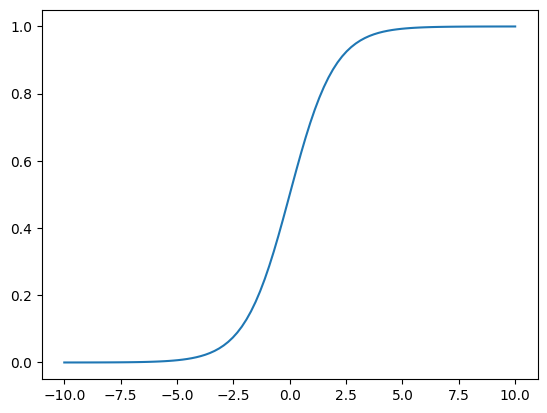

In [25]:
plt.plot(x,y)

In [26]:
def log_loss(y , y_hat):
  loss = y*np.log(y_hat)+(1-y)*np.log(1-y_hat)
  return -loss

In [27]:
log_loss(1 , 0.99)

0.01005033585350145

In [31]:
log_loss(0 , 0.87)

2.0402208285265546

In [32]:
cols = ['Day Mins', 'Eve Mins', 'Night Mins', 'CustServ Calls', 'Account Length']

In [33]:
y = churn["Churn"]

In [35]:
y = np.array(y).reshape(len(y), 1) #Reshaping our data to (m,1) shape
X = churn[cols]
X.shape

(5700, 5)

In [37]:
y

array([[0],
       [0],
       [0],
       ...,
       [1],
       [1],
       [1]])

In [38]:
from sklearn.model_selection import train_test_split

X_tr_cv, X_test, y_tr_cv, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
X_train, X_val, y_train, y_val = train_test_split(X_tr_cv, y_tr_cv, test_size=0.25,random_state=1)
X_train.shape

(3420, 5)

In [39]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [40]:
scaler.fit_transform(X_train)

array([[-1.8525591 , -0.54121117,  1.87596728,  0.0724823 ,  2.13378709],
       [ 0.93155078,  1.05292599,  0.39854651, -0.54879454, -0.81991418],
       [ 0.46912157,  0.11462924,  1.13324217,  0.0724823 , -2.27130187],
       ...,
       [-0.52565742, -0.04014136, -0.68543069,  0.69375914,  0.55508469],
       [-0.94359172, -0.58957698, -0.37428909,  1.93631281, -0.36158122],
       [-0.58604336,  2.40910335,  1.70935597,  0.69375914, -0.25972945]])

In [41]:
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

X_train

array([[-1.8525591 , -0.54121117,  1.87596728,  0.0724823 ,  2.13378709],
       [ 0.93155078,  1.05292599,  0.39854651, -0.54879454, -0.81991418],
       [ 0.46912157,  0.11462924,  1.13324217,  0.0724823 , -2.27130187],
       ...,
       [-0.52565742, -0.04014136, -0.68543069,  0.69375914,  0.55508469],
       [-0.94359172, -0.58957698, -0.37428909,  1.93631281, -0.36158122],
       [-0.58604336,  2.40910335,  1.70935597,  0.69375914, -0.25972945]])

In [42]:
from sklearn.linear_model import LogisticRegression

In [43]:
model = LogisticRegression()

In [44]:
model.fit(X_train, y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression()

In [45]:
print(model.coef_)

[[0.6844725  0.29104522 0.13637423 0.79640697 0.0613349 ]]


In [46]:
model.predict(X_train)

array([0, 1, 1, ..., 1, 1, 1])

In [47]:
def accuracy(y_true, y_pred):
  y_true = y_true.reshape(len(y_true))
  return np.sum(y_true == y_pred)/len(y_true)




In [49]:
y_pred = model.predict(X_train)
accuracy(y_train,y_pred )

0.7058479532163743

# New Section